# 14 — Characterization, benchmarking and tomography with `qiskit-experiments`

`qiskit-experiments` (version 0.14.2 here) is a framework to **run and analyze standard device experiments**.
Each experiment builds its circuits and runs them on a backend. It then fits the data and returns results with
uncertainties and figures ([Getting Started](https://qiskit-community.github.io/qiskit-experiments/tutorials/getting_started.html) [1]). The library contains:

* **characterization**: $T_1$, $T_2^*$ (Ramsey), $T_2$ (Hahn echo), $T_\phi$, ZZ coupling, readout error, gate-error amplification, ...
* **randomized benchmarking**: standard, interleaved and purity RB, layer fidelity;
* **tomography**: state and process tomography, also with readout-error mitigation;
* **quantum volume**;
* a **framework** to combine experiments (`ParallelExperiment`, `BatchExperiment`) and to write new ones.

All experiments run on a **noisy Aer simulator** built from the fake backend `FakeManilaV2`
(a 5-qubit snapshot of `ibmq_manila`). `AerSimulator.from_backend` copies the coupling map, the basis gates, the gate errors,
the readout errors and the $T_1/T_2$ values of the backend into a noise model. We can therefore **compare the fitted values with the "true" values** stored in the backend.

**Based on** (Qiskit Experiments documentation)

* Tutorials: [Getting Started](https://qiskit-community.github.io/qiskit-experiments/tutorials/getting_started.html) [1] (Section 2) and [Writing your own experiment](https://qiskit-community.github.io/qiskit-experiments/tutorials/custom_experiment.html) [2] (Section 2.1)
* How-to: [Work with experiment artifacts](https://qiskit-community.github.io/qiskit-experiments/howtos/artifacts.html) [3] (Section 2)
* Manuals: [T1 Characterization](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t1.html) [4], [T2* Ramsey Characterization](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2ramsey.html) [5], [T2 Hahn Characterization](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2hahn.html) [6] (Sections 2–3)
* Manuals: [Randomized Benchmarking](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/randomized_benchmarking.html) [7] (Section 4) and [Quantum State Tomography](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/state_tomography.html) [8] (Section 5)
* API: [`ProcessTomography`](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.library.tomography.ProcessTomography.html) [9] (Section 5), [`ParallelExperiment`](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.framework.ParallelExperiment.html) [11] and [`BatchExperiment`](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.framework.BatchExperiment.html) [12] (Section 6)
* Manual: [Readout Mitigation](https://qiskit-community.github.io/qiskit-experiments/manuals/measurement/readout_mitigation.html) [10] (Section 7)

The custom `XRep` experiment and the comparisons with the backend values are our own additions.

```bash
pip install qiskit-experiments
```

The numbers of shots and points are small, so the whole notebook runs in less than a minute.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit
from qiskit.circuit.library import SXGate
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

import qiskit, qiskit_aer, qiskit_experiments
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__,
      "| qiskit-experiments", qiskit_experiments.__version__)
pd.set_option("display.width", 160)
T_START = time.time()

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-experiments 0.14.2


## 1. The noisy backend and its "true" properties

The `Target` of `FakeManilaV2` holds `QubitProperties` for each qubit (`t1`, `t2`, `frequency`) and the error rate of each instruction.
We copy these values into a table for later comparison. The simulator uses only 2 CPU threads.

> **GPU option.** This qiskit-aer build supports CUDA, so `AerSimulator.from_backend(fake, device="GPU")` also works. The circuits
> here have only 1–3 qubits. For such small circuits, the CPU is faster than the GPU, because each GPU kernel launch has a fixed cost.
> The cell shows the fallback pattern, with `USE_GPU = False`.

In [2]:
fake = FakeManilaV2()
USE_GPU = False
device = "GPU" if (USE_GPU and "GPU" in AerSimulator().available_devices()) else "CPU"
backend = AerSimulator.from_backend(fake, device=device, max_parallel_threads=2, seed_simulator=1234)
print(backend.name, "| device:", device, "| qubits:", backend.num_qubits)
print("coupling map:", sorted(fake.coupling_map.get_edges()))

tgt = fake.target
rows = []
for q in range(fake.num_qubits):
    p = tgt.qubit_properties[q]
    rows.append({"qubit": q, "T1 [us]": p.t1 * 1e6, "T2 [us]": p.t2 * 1e6,
                 "sx error": tgt["sx"][(q,)].error, "readout error": tgt["measure"][(q,)].error})
true_props = pd.DataFrame(rows).set_index("qubit")
display(true_props.round(5))
print({edge: round(tgt["cx"][edge].error, 5) for edge in [(0, 1), (1, 2)] if edge in tgt["cx"]})

aer_simulator_from(fake_manila) | device: CPU | qubits: 5
coupling map: [(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 4), (4, 3)]


,T1 [us],T2 [us],sx error,readout error
qubit,,,,
0,131.52864,102.20390,0.00016,0.0353
1,124.53550,79.01470,0.00039,0.0219
2,158.61524,25.15090,0.00075,0.0964
3,179.10282,54.36101,0.00021,0.0144
4,144.67316,40.33233,0.00035,0.0186


{(0, 1): 0.00883, (1, 2): 0.01394}


## 2. The experiment framework

This section follows the tutorial [Getting Started](https://qiskit-community.github.io/qiskit-experiments/tutorials/getting_started.html) [1]. Each experiment is a subclass of `BaseExperiment`. It is defined by:

* `physical_qubits`: the qubits it acts on;
* `circuits()`: the list of circuits to run; each circuit has **metadata** (for example the delay value) for the analysis;
* an `analysis` object (a `BaseAnalysis`, often a `CurveAnalysis` that fits a model with `lmfit`);
* `experiment_options` (how the circuits are built), `run_options` (passed to `backend.run`, for example `shots`), `transpile_options`, and analysis options.

`exp.run(backend)` transpiles the circuits, submits the jobs and starts the analysis **asynchronously**. It returns an `ExperimentData` container immediately.
`block_for_results()` waits until the jobs and the analysis are finished. The container then holds:

| attribute / method | contents |
|---|---|
| `data()` | raw counts and the metadata of each circuit |
| `analysis_results(name, dataframe=True)` | fitted quantities (`ufloat` values with errors, `quality`, `chisq`) |
| `figure_names`, `figure(i)` | matplotlib figures from the analysis |
| `artifacts()` | additional outputs, such as the raw `lmfit` fit result |
| `child_data()` | sub-containers for composite experiments |
| `status()`, `job_status()`, `analysis_status()` | progress of the run |

The first example is a $T_1$ experiment on qubit 0 ([T1 Characterization](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t1.html) [4]). It prepares $|1\rangle$, waits for a delay $\tau$ and measures. The analysis fits
$P_1(\tau) = A e^{-\tau/T_1} + B$.

experiment options: [1.00000000e-06 4.79030873e-05 9.48061746e-05] ...
number of circuits: 15
{'xval': np.float64(0.00014170926191409112)}


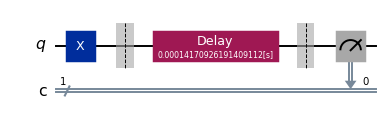

In [3]:
from qiskit_experiments.library import T1

q = 0
T1_true = tgt.qubit_properties[q].t1
delays = np.linspace(1e-6, 5 * T1_true, 15)  # seconds

t1_exp = T1(physical_qubits=(q,), delays=delays)
t1_exp.set_run_options(shots=400)
print("experiment options:", t1_exp.experiment_options.delays[:3], "...")
print("number of circuits:", len(t1_exp.circuits()))
print(t1_exp.circuits()[3].metadata)
t1_exp.circuits()[3].draw("mpl", scale=0.7)

status: ExperimentStatus.DONE | experiment id: b0545792-0053-40d3-933f-9941138e0ce4
first datum: {'1': 380, '0': 20} {'xval': 9.99111111111111e-07}


,name,value,quality,chisq,unit
0433bde8,T1,0.000131+/-0.000005,good,0.632459,s


fitted T1 = 130.7 ± 5.2 us   |   backend T1 = 131.5 us
figures: ['T1_Q0_b0545792.svg']


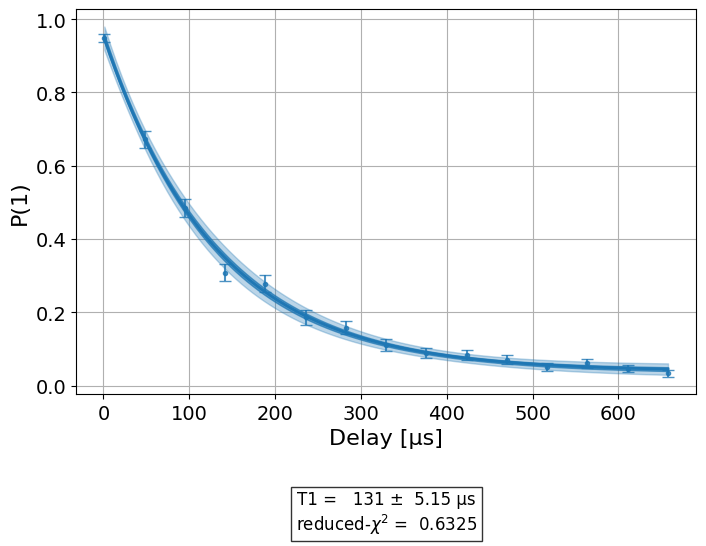

In [4]:
t1_data = t1_exp.run(backend).block_for_results()
print("status:", t1_data.status(), "| experiment id:", t1_data.experiment_id)
print("first datum:", t1_data.data(0)["counts"], t1_data.data(0)["metadata"])

res = t1_data.analysis_results("T1", dataframe=True)
display(res[["name", "value", "quality", "chisq", "unit"]])
t1_fit = res.iloc[0]["value"]          # an uncertainties.ufloat
print(f"fitted T1 = {t1_fit.n*1e6:.1f} ± {t1_fit.s*1e6:.1f} us   |   backend T1 = {T1_true*1e6:.1f} us")
print("figures:", t1_data.figure_names)
display(t1_data.figure(0))

`analysis_results()` without `dataframe=True` is deprecated, so always pass `dataframe=True`. Some analyses attach extra
fields, for example `fitter` in tomography or `EPC_systematic_bounds` in IRB. These fields become **extra columns** of the table.
Use `columns="all"` to see all columns. The `value` column holds `ufloat` objects from the `uncertainties` package:
`.n` is the nominal value and `.s` is the standard error.
The raw fit result is stored as an **artifact** ([Work with experiment artifacts](https://qiskit-community.github.io/qiskit-experiments/howtos/artifacts.html) [3]):

In [5]:
fit = t1_data.artifacts("fit_summary").data
print(type(fit).__name__, "| reduced chi^2 =", round(fit.reduced_chisq, 3))
print({k: f"{v.n:.4g}" for k, v in fit.ufloat_params.items()})

CurveFitResult | reduced chi^2 = 0.632
{'amp': '0.9156', 'tau': '0.0001307', 'base': '0.03895'}


### 2.1 Writing your own experiment

This follows the tutorial [Writing your own experiment](https://qiskit-community.github.io/qiskit-experiments/tutorials/custom_experiment.html) [2] in a reduced form. A minimal custom experiment needs only `circuits()` and an analysis.
The next cell builds an "$X^n$ population" experiment. It applies $n$ X gates and measures $P_1$. On a perfect device, $P_1$ alternates between 0 and 1.
Gate and readout errors slowly reduce the contrast. The analysis is a plain `BaseAnalysis` that returns one `AnalysisResultData`
and one figure.

,name,value
4e4df56f,contrast,0.925286


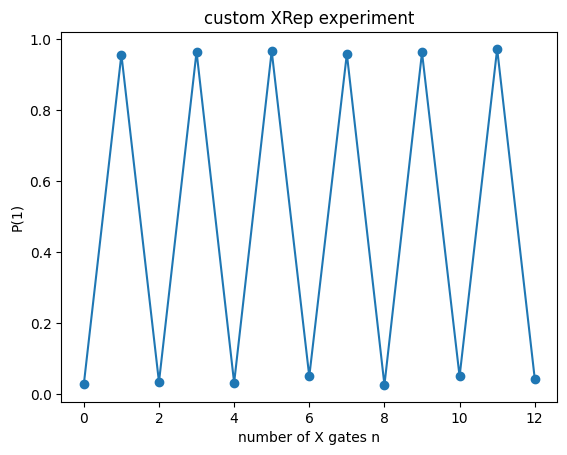

In [6]:
from qiskit_experiments.framework import BaseExperiment, BaseAnalysis, AnalysisResultData, Options
from qiskit_experiments.framework.matplotlib import get_non_gui_ax

class XRepAnalysis(BaseAnalysis):
    def _run_analysis(self, experiment_data):
        ns, p1 = [], []
        for d in experiment_data.data():
            shots = sum(d["counts"].values())
            ns.append(d["metadata"]["n"]); p1.append(d["counts"].get("1", 0) / shots)
        ns, p1 = np.array(ns), np.array(p1)
        # contrast between odd (ideal 1) and even (ideal 0) repetitions
        contrast = p1[ns % 2 == 1].mean() - p1[ns % 2 == 0].mean()
        ax = get_non_gui_ax()
        ax.plot(ns, p1, "o-"); ax.set_xlabel("number of X gates n"); ax.set_ylabel("P(1)")
        ax.set_title("custom XRep experiment")
        return [AnalysisResultData("contrast", contrast)], [ax.get_figure()]

class XRep(BaseExperiment):
    def __init__(self, physical_qubits, max_n=12, backend=None):
        super().__init__(physical_qubits, analysis=XRepAnalysis(), backend=backend)
        self.set_experiment_options(max_n=max_n)

    @classmethod
    def _default_experiment_options(cls):
        opts = super()._default_experiment_options()
        opts.max_n = 12
        return opts

    def circuits(self):
        circs = []
        for n in range(self.experiment_options.max_n + 1):
            qc = QuantumCircuit(1)
            for _ in range(n):
                qc.x(0); qc.barrier()
            qc.measure_all()
            qc.metadata = {"n": n}
            circs.append(qc)
        return circs

xrep_data = XRep((0,), max_n=12).run(backend, shots=500).block_for_results()
display(xrep_data.analysis_results(dataframe=True)[["name", "value"]])
display(xrep_data.figure(0))

## 3. Coherence: $T_2^*$ (Ramsey) and $T_2$ (Hahn echo)

* **`T2Ramsey`** ([manual](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2ramsey.html) [5]): $\sqrt{X}$ – delay $\tau$ – phase $2\pi f_{\rm osc}\tau$ – $\sqrt{X}$. The added "virtual detuning" $f_{\rm osc}$ makes
  the signal oscillate. The fit model is $P_1(\tau)=A e^{-\tau/T_2^*}\cos(2\pi f\tau+\phi)+B$. On hardware, low-frequency noise
  makes $T_2^*\le T_2$. The noise of the simulator is purely Markovian (thermal relaxation), so here we expect $T_2^*\approx T_2$.
* **`T2Hahn`** ([manual](https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2hahn.html) [6]): $\sqrt{X}$ – $\tau/2$ – $X$ – $\tau/2$ – $\sqrt{X}$. The echo refocuses quasi-static noise. The fit model is a plain
  exponential decay with the constant $T_2$.

Choose the sampling so that the virtual oscillation is well resolved. With 20 points over $2T_2$ and $f_{\rm osc}=100$ kHz, the signal would
be **aliased**: the fit would still converge, but to a wrong frequency. Here we use 40 points over $1.5\,T_2$ and $f_{\rm osc}=25$ kHz (about 4 periods).

,name,value,quality,chisq
9d0780a7,Frequency,(2.496+/-0.009)e+04,good,0.718891
86b30a2a,T2star,0.000100+/-0.000006,good,0.718891


,name,value,quality,chisq
28f28436,T2,0.000116+/-0.000016,good,0.782461


Ramsey frequency = 24.96 ± 0.09 kHz (set: 25 kHz)
T2* = 100.3 ± 5.5 us | T2(Hahn) = 116.1 ± 15.9 us | backend T2 = 102.2 us


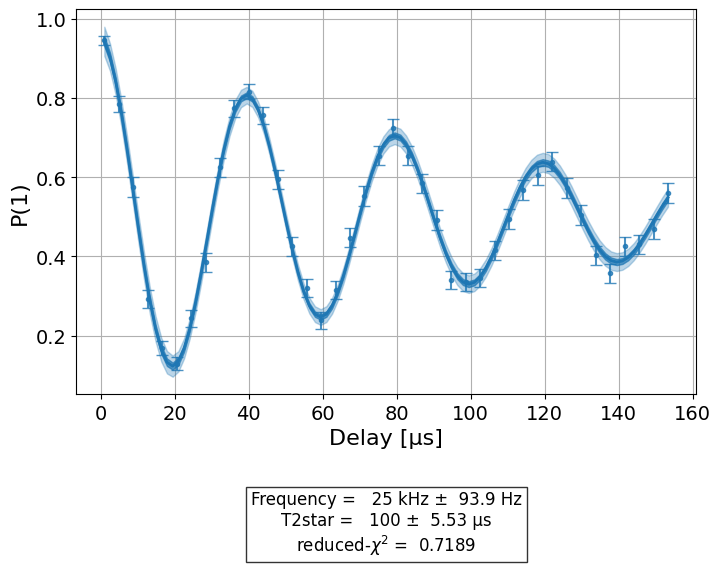

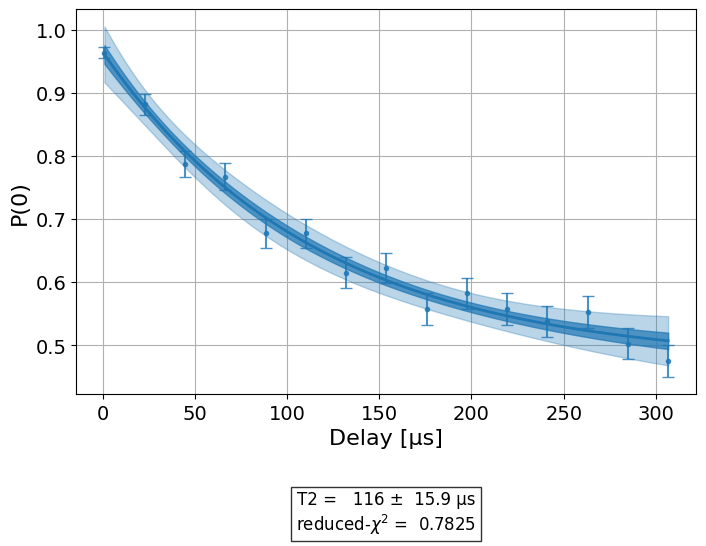

In [7]:
from qiskit_experiments.library import T2Ramsey, T2Hahn

T2_true = tgt.qubit_properties[q].t2
ramsey = T2Ramsey((q,), delays=np.linspace(1e-6, 1.5 * T2_true, 40), osc_freq=25e3)
ramsey.set_run_options(shots=400)
ramsey_data = ramsey.run(backend).block_for_results()
display(ramsey_data.analysis_results(dataframe=True)[["name", "value", "quality", "chisq"]])

hahn = T2Hahn((q,), delays=np.linspace(1e-6, 3 * T2_true, 15), num_echoes=1)
hahn.set_run_options(shots=400)
hahn_data = hahn.run(backend).block_for_results()
display(hahn_data.analysis_results(dataframe=True)[["name", "value", "quality", "chisq"]])

t2s = ramsey_data.analysis_results("T2star", dataframe=True).iloc[0]["value"]
t2h = hahn_data.analysis_results("T2", dataframe=True).iloc[0]["value"]
fr = ramsey_data.analysis_results("Frequency", dataframe=True).iloc[0]["value"]
print(f"Ramsey frequency = {fr.n/1e3:.2f} ± {fr.s/1e3:.2f} kHz (set: 25 kHz)")
print(f"T2* = {t2s.n*1e6:.1f} ± {t2s.s*1e6:.1f} us | T2(Hahn) = {t2h.n*1e6:.1f} ± {t2h.s*1e6:.1f} us | backend T2 = {T2_true*1e6:.1f} us")
display(ramsey_data.figure(0)); display(hahn_data.figure(0))

## 4. Randomized benchmarking

This section follows the manual [Randomized Benchmarking](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/randomized_benchmarking.html) [7].

**Standard RB** applies random sequences of $m$ Clifford gates, followed by the inverse of the sequence. The ideal result is therefore $|0\rangle$.
The experiment measures the survival probability. The average over random sequences turns any noise into a depolarizing channel, so

$$P_0(m) = A\,\alpha^m + B,\qquad \mathrm{EPC} = \frac{2^n-1}{2^n}(1-\alpha).$$

EPC is the error per Clifford. The analysis also estimates the **error per gate (EPG)** from the average number of each basis gate per Clifford.
For one qubit, the transpiled Cliffords consist of `sx`, `x` and `rz`. The `rz` gate is virtual and has no error, and the analysis assumes the same error for `x` as for `sx`.

The error rate in the target is an *average gate infidelity*, the same quantity as EPG, so we can compare them directly. The 1-qubit `sx` error on Manila is about $10^{-4}$–$10^{-3}$.
We therefore need long sequences (up to 2000 Cliffords) to see a decay. For 2 qubits, the CX error dominates, and short sequences are enough.

,name,value,quality
cc0a8a08,alpha,0.99933+/-0.00020,good
47a707ca,EPC,0.00033+/-0.00010,good
aa1abeaa,EPG_rz,0.0+/-0,good
7bcd0040,EPG_sx,0.00040+/-0.00012,good
41a3e7f4,EPG_x,0.00040+/-0.00012,good


EPG_sx (RB) = 3.96e-04 ± 1.2e-04   |   backend sx error = 1.55e-04


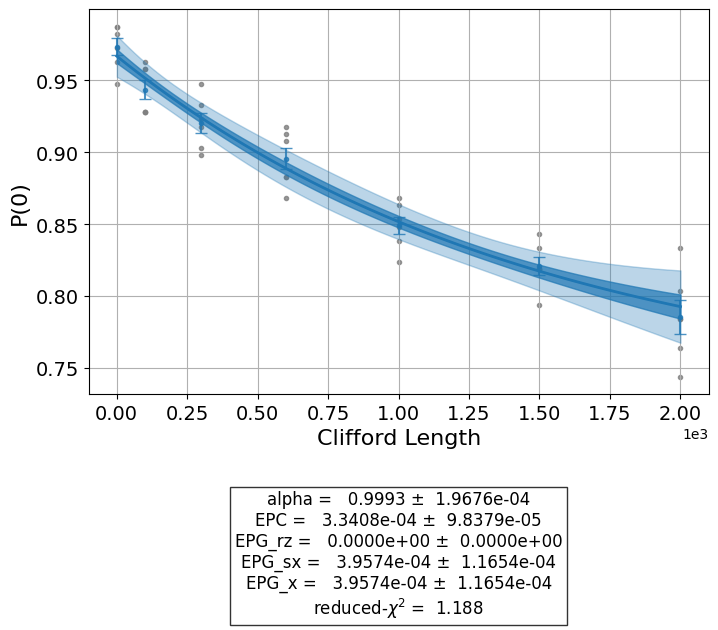

In [8]:
from qiskit_experiments.library import StandardRB, InterleavedRB

lengths_1q = [1, 100, 300, 600, 1000, 1500, 2000]
rb1 = StandardRB((q,), lengths=lengths_1q, num_samples=6, seed=7, backend=backend)
rb1.set_run_options(shots=200)
rb1_data = rb1.run(backend).block_for_results()
display(rb1_data.analysis_results(dataframe=True)[["name", "value", "quality"]])
epg_sx = rb1_data.analysis_results("EPG_sx", dataframe=True).iloc[0]["value"]
print(f"EPG_sx (RB) = {epg_sx.n:.2e} ± {epg_sx.s:.1e}   |   backend sx error = {tgt['sx'][(q,)].error:.2e}")
display(rb1_data.figure(0))

,name,value,quality
c7fb7586,alpha,0.9870+/-0.0035,bad
d9960531,EPC,0.0097+/-0.0026,bad
6046a2a7,EPG_cx,0.0065+/-0.0017,bad


EPG_cx (RB) = 6.46e-03 ± 1.7e-03   |   backend cx(0,1) error = 8.83e-03


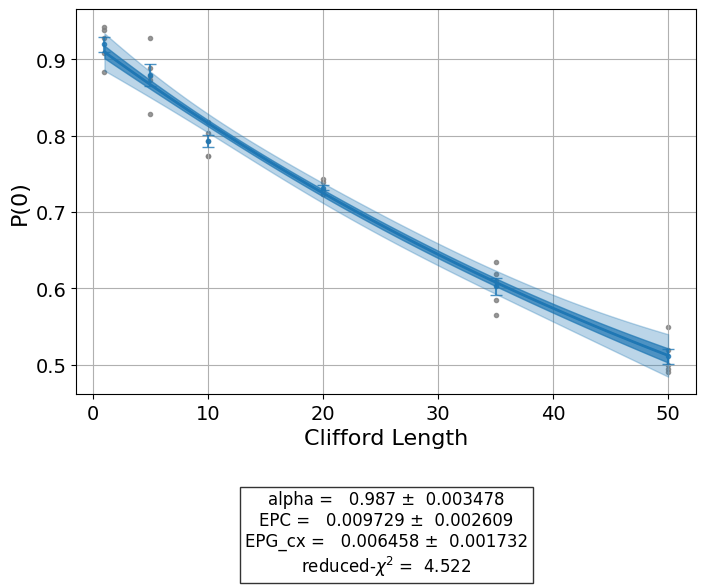

In [9]:
rb2 = StandardRB((0, 1), lengths=[1, 5, 10, 20, 35, 50], num_samples=5, seed=7, backend=backend)
rb2.set_run_options(shots=200)
rb2_data = rb2.run(backend).block_for_results()
display(rb2_data.analysis_results(dataframe=True)[["name", "value", "quality"]])
epg_cx = rb2_data.analysis_results("EPG_cx", dataframe=True).iloc[0]["value"]
print(f"EPG_cx (RB) = {epg_cx.n:.2e} ± {epg_cx.s:.1e}   |   backend cx(0,1) error = {tgt['cx'][(0, 1)].error:.2e}")
display(rb2_data.figure(0))

For two qubits, the analysis assumes by default that the **1-qubit gates have no error** when it assigns the EPG to `cx`. To correct this, pass the
1-qubit EPGs from above (`rb2.analysis.set_options(epg_1_qubit=...)`). The 1-qubit errors are more than 10 times smaller than the CX error, so the
correction is small here.

### Interleaved RB

**Interleaved RB** (IRB) runs a reference RB sequence and a second sequence in which a target gate $G$ follows each Clifford.
The ratio of the two decay rates gives the error of $G$ alone:

$$\mathrm{EPC}_G = \frac{2^n-1}{2^n}\Bigl(1-\frac{\alpha_c}{\alpha}\Bigr).$$

The estimate has systematic bounds. The analysis reports them as `EPC_systematic_err` / `EPC_systematic_bounds`. For a single `sx` gate on Manila,
IRB measures an error of about $10^{-4}$. This is close to the resolution limit of a few hundred shots, so the fit often has `quality="bad"`
and a large relative error. With 2 qubits this is easier, so we interleave the CX gate.

,name,value,quality
c2886412,alpha,0.9794+/-0.0024,good
c277f1b1,alpha_c,0.9838+/-0.0025,good
f4ede5c3,EPC,0.0121+/-0.0019,good


IRB EPC(cx) = 1.21e-02 ± 1.9e-03   |   backend cx(0,1) error = 8.83e-03
systematic bounds: [0, 0.03085821702253616]


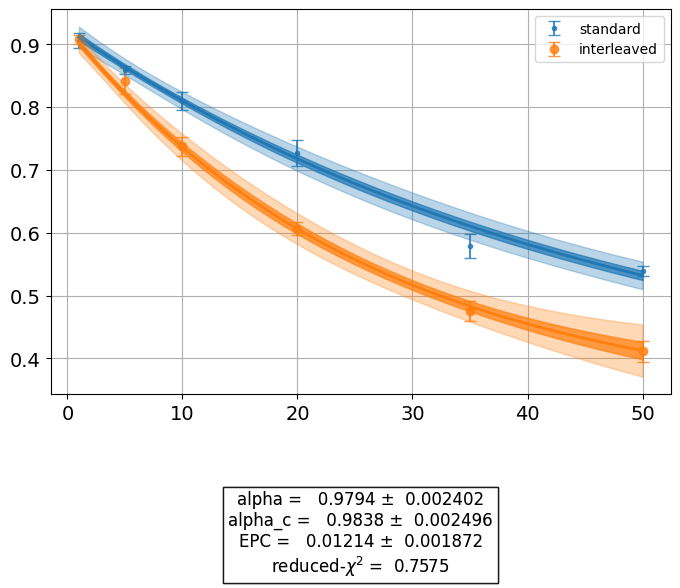

In [10]:
from qiskit.circuit.library import CXGate

irb = InterleavedRB(CXGate(), (0, 1), lengths=[1, 5, 10, 20, 35, 50], num_samples=5, seed=7, backend=backend)
irb.set_run_options(shots=200)
irb_data = irb.run(backend).block_for_results()
irb_res = irb_data.analysis_results(dataframe=True)
display(irb_res[["name", "value", "quality"]])
epc_cx = irb_data.analysis_results("EPC", dataframe=True).iloc[0]
print(f"IRB EPC(cx) = {epc_cx['value'].n:.2e} ± {epc_cx['value'].s:.1e}   |   backend cx(0,1) error = {tgt['cx'][(0, 1)].error:.2e}")
print("systematic bounds:", epc_cx.get("EPC_systematic_bounds"))
display(irb_data.figure(0))

**Comparison of the RB values with the backend values.** The exact values change with the random seeds.

* *1 qubit:* `EPG_sx` is about 2σ from the `sx` error of the target (about 1.6×10⁻⁴), and the uncertainty is large. With only 6 random sequences per length,
  the variation between sequences dominates. A larger `num_samples` would reduce the uncertainty. The noise model also adds thermal relaxation during each gate
  to the depolarizing part, so a slightly higher RB value is expected.
* *2 qubits:* `EPG_cx` from standard RB and `EPC` from interleaved RB are both close to the CX(0,1) error of the target (about 0.9×10⁻²). The IRB value is inside its
  reported systematic bounds. The standard 2-qubit fit with only 5 samples sometimes has `quality="bad"` (the reduced $\chi^2$ or the relative error is outside
  the tolerances), even when the value itself is reasonable.

## 5. State and process tomography

This section follows the manual [Quantum State Tomography](https://qiskit-community.github.io/qiskit-experiments/manuals/verification/state_tomography.html) [8] and the API page of [`ProcessTomography`](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.library.tomography.ProcessTomography.html) [9].

**`StateTomography`** measures the output of the circuit in all $3^n$ Pauli bases and reconstructs the density matrix $\rho$. The default fitter is
`linear_inversion`. It is followed by a projection onto the nearest positive semidefinite matrix with unit trace (`rescale_positive=True`, `rescale_trace=True`).
Constrained least-squares fitters are also available, `"cvxpy_linear_lstsq"` and `"cvxpy_gaussian_lstsq"`. Select them with `analysis.set_options(fitter=...)`.
Pass `target=` to compute the fidelity with respect to a state other than the ideal output of the circuit.

For a Bell state $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$, three effects lower the fidelity: the CX error, decoherence during the gate and,
**most of all**, the readout error. Plain tomography does not correct readout errors. `MitigatedStateTomography` adds a readout calibration
and corrects for them.

number of tomography circuits: 9


,name,value
a486c175,state_fidelity,0.916833
70d2907c,positive,True


fitter: linear_inversion | rescale_positive: True


Bell fidelity: raw = 0.9168 | readout-mitigated = 0.9788


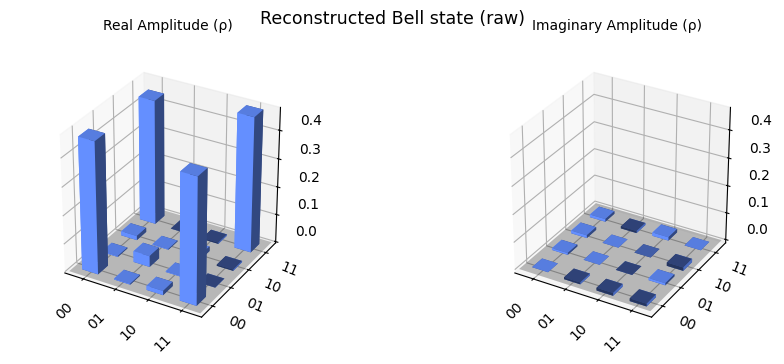

In [11]:
from qiskit_experiments.library import StateTomography, MitigatedStateTomography
from qiskit.visualization import plot_state_city

bell = QuantumCircuit(2)
bell.h(0); bell.cx(0, 1)

qst = StateTomography(bell, physical_qubits=(0, 1), backend=backend)
qst.set_run_options(shots=500)
print("number of tomography circuits:", len(qst.circuits()))
qst_data = qst.run(backend).block_for_results()
display(qst_data.analysis_results(dataframe=True)[["name", "value"]].iloc[1:])
rho = qst_data.analysis_results("state", dataframe=True).iloc[0]["value"]
print("fitter:", qst.analysis.options.fitter, "| rescale_positive:", qst.analysis.options.rescale_positive)

mqst = MitigatedStateTomography(bell, physical_qubits=(0, 1), backend=backend)
mqst.set_run_options(shots=500)
mqst_data = mqst.run(backend).block_for_results()
f_raw = qst_data.analysis_results("state_fidelity", dataframe=True).iloc[0]["value"]
f_mit = mqst_data.analysis_results("state_fidelity", dataframe=True).iloc[0]["value"]
print(f"Bell fidelity: raw = {f_raw:.4f} | readout-mitigated = {f_mit:.4f}")
plot_state_city(rho, title="Reconstructed Bell state (raw)", figsize=(9, 3.5))

**`ProcessTomography`** prepares $4^n$ input states (Pauli eigenstates) and measures each output in $3^n$ bases. For 2 qubits, this gives $144$ circuits.
It reconstructs the **Choi matrix** of the channel. `process_fidelity` is computed with respect to the ideal unitary. The average gate fidelity is
$F_{\rm avg} = (d\,F_{\rm pro}+1)/(d+1)$. Its complement, the average gate error, is the quantity that RB measures.

The process fidelity also includes state-preparation-and-measurement (SPAM) errors. RB does not include them. We therefore expect $1-F_{\rm avg}^{\rm QPT}$ to be **larger** than the RB/IRB CX error.

number of process-tomography circuits: 144


,name,value
464cbd74,process_fidelity,0.863551
34136b23,completely_positive,True
bc6e47e9,trace_preserving,False


process fidelity = 0.8636 -> average gate error = 0.1092
average gate fidelity (qiskit.quantum_info, normalized Choi) = 0.8908
compare: IRB EPC(cx) = 0.0121, backend cx error = 0.0088


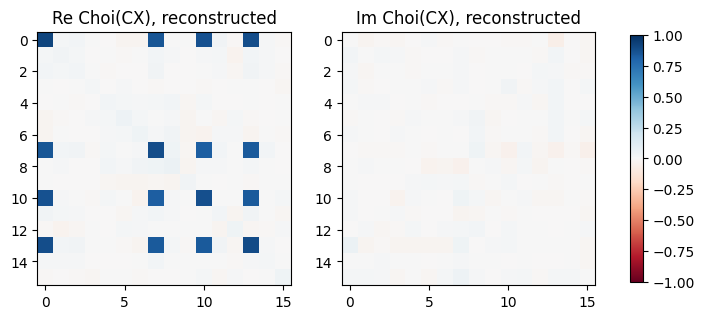

In [12]:
from qiskit_experiments.library import ProcessTomography
from qiskit.quantum_info import average_gate_fidelity, Choi

cx_circ = QuantumCircuit(2)
cx_circ.cx(0, 1)
qpt = ProcessTomography(cx_circ, physical_qubits=(0, 1), backend=backend)
qpt.set_run_options(shots=300)
print("number of process-tomography circuits:", len(qpt.circuits()))
qpt_data = qpt.run(backend).block_for_results()
display(qpt_data.analysis_results(dataframe=True)[["name", "value"]].iloc[1:])
choi = qpt_data.analysis_results("state", dataframe=True).iloc[0]["value"]
F_pro = qpt_data.analysis_results("process_fidelity", dataframe=True).iloc[0]["value"]
d = 4
print(f"process fidelity = {F_pro:.4f} -> average gate error = {1 - (d*F_pro + 1)/(d + 1):.4f}")
print(f"average gate fidelity (qiskit.quantum_info, normalized Choi) = {average_gate_fidelity(Choi(choi.data * d / np.trace(choi.data)), Operator(cx_circ)):.4f}")
print(f"compare: IRB EPC(cx) = {epc_cx['value'].n:.4f}, backend cx error = {tgt['cx'][(0, 1)].error:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, part, name in zip(axs, [choi.data.real, choi.data.imag], ["Re", "Im"]):
    im = ax.imshow(part, cmap="RdBu", vmin=-1, vmax=1); ax.set_title(f"{name} Choi(CX), reconstructed")
fig.colorbar(im, ax=axs, shrink=0.8); plt.show()

**Observations.**

* The reconstructed CX has an average gate error of about 0.1, about 10 times the RB/IRB value. Almost all of this is SPAM: the readout errors of qubits 0 and 1
  (3.5% and 2.2%) affect each of the 144 circuits. `MitigatedProcessTomography` would remove most of the readout part.
* `trace_preserving` is `False`. The default `linear_inversion` fit is only rescaled to be completely positive. It does not enforce trace preservation.
  To enforce it, use `qpt.analysis.set_options(fitter="cvxpy_gaussian_lstsq", fitter_options={"trace_preserving": True})`.

## 6. Composite experiments: `ParallelExperiment` and `BatchExperiment`

* **[`ParallelExperiment`](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.framework.ParallelExperiment.html)** [11] combines experiments on **disjoint qubits** into the *same* circuits, so they run at the same time. This is the
  usual way to characterize a whole chip, and it also includes crosstalk.
* **[`BatchExperiment`](https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.framework.BatchExperiment.html)** [12] runs experiments (which may share qubits) **one after another** in the same job(s), so the analyses can run together.

Both return a parent `ExperimentData`. With `flatten_results=True`, all child results **and figures** move into the table of the parent.
They are labelled by `experiment` and `components` (qubits), and `child_data()` is empty. With `flatten_results=False`, the results stay in
separate `child_data(i)` containers for each experiment.

parallel circuits: 15 (one set for all 5 qubits)


,T1 fit [us],± [us],T1 backend [us],quality
qubit,,,,
0,138.9,7.2,131.5,good
1,125.7,6.0,124.5,good
2,166.8,13.1,158.6,bad
3,173.3,10.4,179.1,good
4,135.8,6.7,144.7,good


child containers kept: 0 | figures: ['T1_Q0_c7dac866.svg', 'T1_Q1_236d3be4.svg', 'T1_Q2_ce37ad77.svg', 'T1_Q3_b0b8ad75.svg', 'T1_Q4_c114e643.svg']


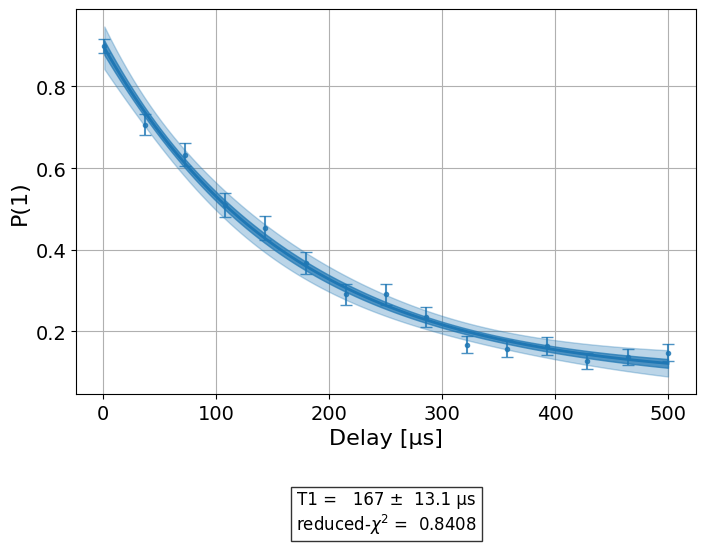

In [13]:
from qiskit_experiments.framework import ParallelExperiment, BatchExperiment

qubits = [0, 1, 2, 3, 4]
t1_delays = np.linspace(1e-6, 500e-6, 15)
par = ParallelExperiment([T1((i,), t1_delays) for i in qubits], backend=backend, flatten_results=True)
print("parallel circuits:", len(par.circuits()), "(one set for all", len(qubits), "qubits)")
par_data = par.run(backend, shots=300).block_for_results()

tab = par_data.analysis_results("T1", dataframe=True)
cmp = pd.DataFrame({
    "qubit": qubits,
    "T1 fit [us]": [v.n * 1e6 for v in tab["value"]],
    "± [us]": [v.s * 1e6 for v in tab["value"]],
    "T1 backend [us]": [true_props.loc[i, "T1 [us]"] for i in qubits],
    "quality": list(tab["quality"]),
}).set_index("qubit")
display(cmp.round(1))
print("child containers kept:", len(par_data.child_data()), "| figures:", par_data.figure_names)
display(par_data.figure(2))

In [14]:
batch = BatchExperiment(
    [T1((q,), delays), T2Hahn((q,), np.linspace(1e-6, 3 * T2_true, 15)), T2Ramsey((q,), np.linspace(1e-6, 1.5 * T2_true, 40), osc_freq=25e3)],
    backend=backend, flatten_results=True,
)
batch_data = batch.run(backend, shots=300).block_for_results()
display(batch_data.analysis_results(dataframe=True)[["name", "experiment", "components", "value", "quality"]])
print("figures in the parent container:", batch_data.figure_names)

,name,experiment,components,value,quality
a4aee889,T1,T1,[Q0],0.000129+/-0.000006,good
1aaaf8dd,T2,T2Hahn,[Q0],(8.6+/-1.3)e-05,good
5dc93325,Frequency,T2Ramsey,[Q0],(2.519+/-0.010)e+04,good
622512de,T2star,T2Ramsey,[Q0],0.000118+/-0.000008,good


figures in the parent container: ['T1_Q0_bf9477d2.svg', 'T2Hahn_Q0_0264b5d7.svg', 'T2Ramsey_Q0_165688a9.svg']


## 7. Readout-error characterization and mitigation

This section follows the manual [Readout Mitigation](https://qiskit-community.github.io/qiskit-experiments/manuals/measurement/readout_mitigation.html) [10].

`LocalReadoutError` prepares $|0\cdots0\rangle$ and $|1\cdots1\rangle$ (only 2 circuits). It builds an independent $2\times2$ **assignment matrix**
$A_q[i,j]=P(\text{measure } i\mid\text{prepared } j)$ for each qubit. Its single result is a `LocalReadoutMitigator`. The mitigator applies
$A^{-1}=\bigotimes_q A_q^{-1}$ to measured distributions. The output is a *quasi*-probability distribution, so it can contain small negative entries.
`CorrelatedReadoutError` instead measures the full $2^n\times2^n$ matrix with $2^n$ circuits.

The plot is off by default, because the figure grows as $2^n$. We switch it on with `analysis.set_options(plot=True)`.

LocalReadoutMitigator
qubit 0: A = [[0.967, 0.032], [0.033, 0.968]],  mean assignment error = 0.0325 | backend = 0.0353
qubit 1: A = [[0.976, 0.022], [0.024, 0.978]],  mean assignment error = 0.0230 | backend = 0.0219
qubit 2: A = [[0.9, 0.094], [0.1, 0.906]],  mean assignment error = 0.0975 | backend = 0.0964


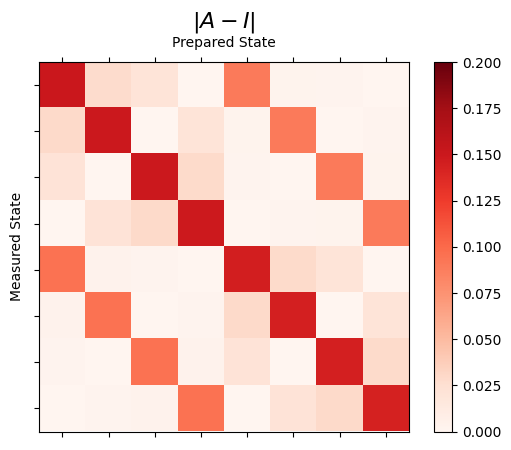

In [15]:
from qiskit_experiments.library import LocalReadoutError

ro_qubits = (0, 1, 2)
ro_exp = LocalReadoutError(ro_qubits, backend=backend)
ro_exp.analysis.set_options(plot=True)
ro_exp.set_run_options(shots=2000)
ro_data = ro_exp.run(backend).block_for_results()
mitigator = ro_data.analysis_results("Local Readout Mitigator", dataframe=True).iloc[0]["value"]
print(type(mitigator).__name__)

for i, qq in enumerate(ro_qubits):
    A = mitigator.assignment_matrix(qq)
    meas_err = 0.5 * (A[1, 0] + A[0, 1])
    print(f"qubit {qq}: A = {np.round(A, 3).tolist()},  mean assignment error = {meas_err:.4f} | backend = {tgt['measure'][(qq,)].error:.4f}")
display(ro_data.figure(0))

Next we apply the mitigator to a 3-qubit GHZ state, measured on the same physical qubits. We measure qubit $k$ into clbit $k$,
so the `classical_bits` order of the counts matches the `qubits` order of the mitigator. An *initial layout* places the virtual qubits on
physical qubits 0, 1 and 2.

distance to ideal GHZ (total variation): raw = 0.1560 | mitigated = 0.0212
<Z0 Z1>: raw = 0.8625 | mitigated = 0.9670 ± 0.0222 | ideal = 1


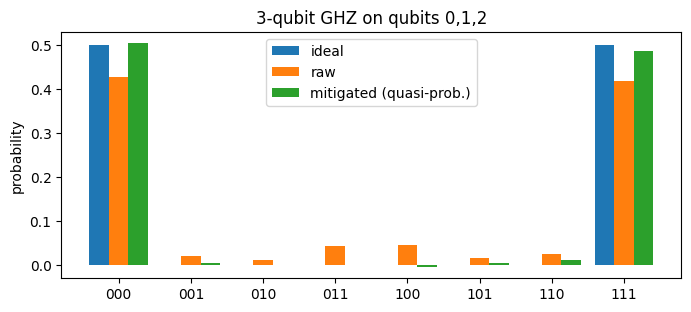

In [16]:
from qiskit import transpile

ghz = QuantumCircuit(3)
ghz.h(0); ghz.cx(0, 1); ghz.cx(1, 2)
ghz.measure_all()
tqc = transpile(ghz, backend, initial_layout=list(ro_qubits), seed_transpiler=1)
counts = backend.run(tqc, shots=4000).result().get_counts()

quasi = mitigator.quasi_probabilities(counts)
ideal = {"000": 0.5, "111": 0.5}
labels = [format(i, "03b") for i in range(8)]
raw_p = np.array([counts.get(b, 0) for b in labels]) / 4000
mit_p = np.array([quasi.get(int(b, 2), 0.0) for b in labels])
ideal_p = np.array([ideal.get(b, 0.0) for b in labels])
tvd = lambda p: 0.5 * np.abs(p - ideal_p).sum()
print(f"distance to ideal GHZ (total variation): raw = {tvd(raw_p):.4f} | mitigated = {tvd(mit_p):.4f}")

# <ZZZ> parity-like observable: ideal GHZ value of <Z0 Z1 Z2> is 0, of <Z0 Z1> is +1
zz_raw = sum((1 if (b[-1] == b[-2]) else -1) * c for b, c in counts.items()) / 4000
diag_z0z1 = np.array([(-1) ** (((i >> 0) & 1) ^ ((i >> 1) & 1)) for i in range(8)])  # O(x) for integer outcome x
zz_mit, zz_std = mitigator.expectation_value(counts, diagonal=diag_z0z1, qubits=list(ro_qubits))
print(f"<Z0 Z1>: raw = {zz_raw:.4f} | mitigated = {zz_mit:.4f} ± {zz_std:.4f} | ideal = 1")

x = np.arange(8)
plt.figure(figsize=(8, 3.2))
plt.bar(x - 0.27, ideal_p, 0.27, label="ideal")
plt.bar(x, raw_p, 0.27, label="raw")
plt.bar(x + 0.27, mit_p, 0.27, label="mitigated (quasi-prob.)")
plt.xticks(x, labels); plt.ylabel("probability"); plt.title("3-qubit GHZ on qubits 0,1,2"); plt.legend(); plt.show()

## 8. Not covered: experiments that need pulse-level control

Older releases of qiskit-experiments had a **calibration** module that built and updated *pulse schedules*:
`Calibrations`/`BackendCalibrations`, `Rabi`/`EFRabi` and `RoughAmplitudeCal`, `RoughDrag(Cal)`, `RoughFrequencyCal`, `QubitSpectroscopy`/`EFSpectroscopy`,
`ResonatorSpectroscopy`, `CrossResonanceHamiltonian`/`EchoedCrossResonanceHamiltonian`, `FineAmplitudeCal`/`FineDragCal`/`FineFrequencyCal`,
and others. These need `qiskit.pulse`, which **Qiskit 2.x removed**. The pulse-based experiments and the calibration
framework are therefore **not in qiskit-experiments 0.14.2**. They also cannot run on a fake backend with Aer, because Aer has no pulse simulator here.

The gate-level *characterization* experiments of that workflow are still in the library. They run on Aer like the experiments above:
`FineAmplitude`/`FineXAmplitude`/`FineSXAmplitude`, `FineDrag`, `HalfAngle`, `RamseyXY`, `FineFrequency`, `ZZRamsey`, `Tphi`, `ReadoutAngle` and
`MultiStateDiscrimination`. The last two need level-1 (IQ) data, which Aer does not produce for these backends. On a perfectly calibrated simulator,
these experiments mostly report errors close to zero. Only the step that feeds their results back into pulse parameters needs pulse control.

## 9. Summary, notes and references

| experiment | fitted | compared with |
|---|---|---|
| `T1` | $T_1$ | `target.qubit_properties[q].t1` |
| `T2Ramsey` | $T_2^*$, detuning | `.t2` (about equal on Aer: no 1/f noise) |
| `T2Hahn` | $T_2$ | `.t2` |
| `StandardRB` 1q / 2q | $\alpha$, EPC, EPG_sx / EPG_cx | `target["sx"/"cx"][qargs].error` |
| `InterleavedRB` | EPC of the interleaved gate (+ systematic bounds) | `target["cx"][(0,1)].error` |
| `StateTomography` | $\rho$, state fidelity | ideal Bell state |
| `ProcessTomography` | Choi matrix, process fidelity | ideal CX (includes SPAM) |
| `LocalReadoutError` | assignment matrices → `LocalReadoutMitigator` | `target["measure"][(q,)].error` |

**Notes on the installed version (0.14.2 with Qiskit 2.x and Aer 0.17)**

* Always call `analysis_results(..., dataframe=True)`. The old return value, a list of `AnalysisResult`, is deprecated. Values are `ufloat`s (`.n`, `.s`). Tomography values are
  `DensityMatrix`/`Choi` objects or floats.
* `T2Ramsey`: choose `osc_freq` and the delay spacing so that the fringes are resolved (several points per period). Otherwise the fit converges to an
  aliased frequency, and the $T_2^*$ estimate is not reliable.
* 1-qubit RB/IRB on a good qubit needs sequences of thousands of Cliffords. IRB of an `sx` gate (about $10^{-4}$) is at the resolution limit of runs with few shots.
  The fit often has `quality="bad"`.
* `LocalReadoutError` does not create a plot unless you set `analysis.set_options(plot=True)`.
* The default tomography fitter is `linear_inversion` with a PSD rescale, so `ProcessTomography` reports `trace_preserving=False`. Use a `cvxpy` fitter with `trace_preserving=True` if you need trace preservation.
* With `flatten_results=True`, a composite `ExperimentData` has **no** `child_data()`. Results and figures are in the parent.
* `run()` is asynchronous. Always call `block_for_results()` (or check `status()`) before you read results.

**References** (Qiskit Experiments documentation pages)

1. Tutorial, Getting Started: <https://qiskit-community.github.io/qiskit-experiments/tutorials/getting_started.html>
2. Tutorial, Writing your own experiment: <https://qiskit-community.github.io/qiskit-experiments/tutorials/custom_experiment.html>
3. How-to, Work with experiment artifacts: <https://qiskit-community.github.io/qiskit-experiments/howtos/artifacts.html>
4. Manual, T1 Characterization: <https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t1.html>
5. Manual, T2* Ramsey Characterization: <https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2ramsey.html>
6. Manual, T2 Hahn Characterization: <https://qiskit-community.github.io/qiskit-experiments/manuals/characterization/t2hahn.html>
7. Manual, Randomized Benchmarking: <https://qiskit-community.github.io/qiskit-experiments/manuals/verification/randomized_benchmarking.html>
8. Manual, Quantum State Tomography: <https://qiskit-community.github.io/qiskit-experiments/manuals/verification/state_tomography.html>
9. API reference, `ProcessTomography`: <https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.library.tomography.ProcessTomography.html>
10. Manual, Readout Mitigation: <https://qiskit-community.github.io/qiskit-experiments/manuals/measurement/readout_mitigation.html>
11. API reference, `ParallelExperiment`: <https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.framework.ParallelExperiment.html>
12. API reference, `BatchExperiment`: <https://qiskit-community.github.io/qiskit-experiments/stubs/qiskit_experiments.framework.BatchExperiment.html>

In [17]:
print(f"total notebook runtime: {time.time() - T_START:.1f} s")

total notebook runtime: 21.6 s
